# C-LiTE: A Lightweight Foundation Model for Cellular Feature Learning

Click to open in: \[[GitHub](https://github.com/TissueImageAnalytics/tiatoolbox/blob/develop/examples/14-clite-cell-feature-learning.ipynb)\]\[[Colab](https://colab.research.google.com/github/TissueImageAnalytics/tiatoolbox/blob/develop/examples/14-clite-cell-feature-learning.ipynb)\]


## About this notebook

This jupyter notebook can be run on any computer with a standard browser and no prior installation of any programming language is required. It can run remotely over the Internet, free of charge, thanks to Google Colaboratory. To connect with Colab, click on one of the two blue checkboxes above. Check that "colab" appears in the address bar. You can right-click on "Open in Colab" and select "Open in new tab" if the left click does not work for you. Familiarize yourself with the drop-down menus near the top of the window. You can edit the notebook during the session, for example substituting your own image files for the image files used in this demo. Experiment by changing the parameters of functions. It is not possible for an ordinary user to permanently change this version of the notebook on GitHub or Colab, so you cannot inadvertently mess it up. Use the notebook's File Menu if you wish to save your own (changed) notebook.

To run the notebook on any platform, except for Colab, set up your Python environment, as explained in the
[README](https://github.com/TIA-Lab/tiatoolbox/blob/master/README.md#install-python-package) file.


## About this demo

C-LiTE is a lightweight, deployment-friendly, **cell-centric foundation model** for H&E histopathology. It is a 22M-parameter ViT-5-S encoder pre-trained with self-supervised learning on more than **60 million** nucleus-centred cell crops (64×64 px at 0.5 µm/px) from 19 cancer types in TCGA.

C-LiTE makes two main changes to a standard pathology foundation model:

- **PI-PatchEmbed.** The pretrained 14×14 patch projection is mapped to a 4×4 projection with a Moore–Penrose pseudoinverse (following FlexiViT's PI-resize). A 64×64 cell crop therefore gives a 16×16 grid of 256 tokens, so the model sees each cell at its native resolution.
- **ViT-5-S backbone with DINOv2-style training.** The encoder uses RMSNorm, QK-norm, LayerScale, 2D rotary position embeddings (RoPE) and 4 register tokens. It is trained as a student–teacher pair, where the teacher is an exponential moving average (EMA) of the student, with DINO and iBOT losses.

We evaluated C-LiTE on 7 benchmark datasets covering mitosis classification, nucleus and cell-type classification, immune-cell phenotyping and hierarchical nucleus-subtype classification. With a frozen encoder and a linear probe, C-LiTE reaches a mean macro-F1 of **0.670**. This is higher than the much larger patch-level foundation models UNI2 (0.646) and Virchow2 (0.628). It is also close to CytoFormer (0.682), a cell-centric model about 30 times larger.

In this notebook, we evaluate C-LiTE with a **linear probe** on the [PanNuke](https://huggingface.co/datasets/RationAI/PanNuke) dataset:

**PanNuke tiles → nucleus-centred 64×64 crops → frozen C-LiTE → CLS features → logistic regression → metrics and visualizations.**

- **Data:** the three PanNuke folds are downloaded from Hugging Face, and one 64×64 crop is cut around the centroid of each nucleus mask.
- **Model:** the C-LiTE inference architecture, built from the checkpoint.
- **Features:** the final CLS token (optionally concatenated with the mean patch token).
- **Splits:** Fold1 = train, Fold2 = validation, Fold3 = test.
- **Classifier:** logistic regression (linear probe).
- **Visualizations:** PCA of patch tokens for individual cells, and t-SNE / UMAP of the CLS features.


## Setting up the environment

### TIAToolbox and dependencies installation

You can skip the following cell if 1) you are not using the Colab plaform or 2) you are using Colab and this is not your first run of the notebook in the current runtime session. If you nevertheless run the cell, you may get an error message, but no harm will be done. On Colab the cell installs `tiatoolbox`, and other prerequisite software. Harmless error messages should be ignored. Outside Colab , the notebook expects `tiatoolbox` to already be installed. (See the instructions in [README](https://github.com/TIA-Lab/tiatoolbox/blob/master/README.md#install-python-package).)


In [1]:
%%bash
apt-get -y install libopenjp2-7-dev libopenjp2-tools libpixman-1-dev | tail -n 1
pip install uv
uv pip install git+https://github.com/TissueImageAnalytics/tiatoolbox.git@develop | tail -n 1
echo "Installation is done."

Processing triggers for man-db (2.12.0-4build2) ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 106.7 MB/s  0:00:00
Installation is done.


Using Python 3.13.16 environment at: /usr
Resolved 216 packages in 1m 04s
Prepared 38 packages in 7.13s
Uninstalled 7 packages in 142ms
Installed 38 packages in 227ms
 + aiobotocore==3.10.0
 + aioitertools==0.13.0
 + async-lru==2.4.0
 + botocore==1.43.117
 - cachetools==6.2.6
 + cachetools==8.0.0
 + comm==0.2.3
 - dask==2026.1.1
 + dask==2026.8.0
 + dicomweb-client==0.61.2
 + donfig==0.8.1.post1
 + flask-cors==6.0.5
 - fsspec==2025.12.0
 + fsspec==2026.9.0
 + glymur==0.14.8
 + imagecodecs==2026.11.11
 - ipywidgets==7.7.1
 + ipywidgets==8.1.9
 + jedi==0.20.1
 + jmespath==1.1.0
 + json5==0.17.3
 + jupyter-builder==1.3.0
 + jupyter-lsp==2.3.1
 + jupyterlab==4.6.6
 + jupyterlab-server==2.28.1
 + marshmallow==4.4.0
 + msgspec==0.22.0
 + numcodecs==0.17.1
 + openslide-bin==4.0.1.2
 + openslide-python==1.4.7
 + pathlib-abc==0.5.2
 + pydicom==3.0.2
 + retrying==1.4.2
 + s3fs==2026.9.0
 - scikit-image==0.25.2
 + scikit-image==0.26.0
 + simpleitk==2.5.7
 - sphinx==8.2.3
 + sphinx==9.1.1
 + tiato

**IMPORTANT**: If you are running this notebook on Colab, then, after running the above cell for the first time, you need to restart the session in order to use the latest version of the packages used by TIAToolbox. To do this, you can click on the *Restart session* message that appears at the bottom of the cell, or use the menu *Runtime→Restart session*. Subsequently, you can use *Runtime→Run all*, **OR** *Runtime→Run after* **OR** run the cells one by one, as you prefer.


**[essential]** Please install the following packages, which are required in this notebook: `datasets` to download PanNuke from Hugging Face and `umap-learn` for the UMAP visualization.


In [2]:
%%bash
pip install datasets umap-learn | tail -n 1

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
s3fs 2026.9.0 requires fsspec<2026.9.1,>=2026.9.0, but you have fsspec 2026.2.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.2.0 which is incompatible.


### Importing related libraries

We import some standard Python modules, together with PyTorch, scikit-learn and Hugging Face `datasets`, and the TIAToolbox logger.


In [3]:
"""Import modules required to run the Jupyter notebook."""

from __future__ import annotations

# Clear logger to use tiatoolbox.logger
import logging

if logging.getLogger().hasHandlers():
    logging.getLogger().handlers.clear()

import csv
import math
import multiprocessing as mp
import random
import shutil
import sys
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F  # noqa: N812
import torchvision.transforms.functional as TF  # noqa: N812
import umap
from datasets import load_dataset
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import label_binarize
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

from tiatoolbox import logger

warnings.filterwarnings("ignore")
mpl.rcParams["figure.dpi"] = 150  # for high resolution figure in notebook
mpl.rcParams["figure.facecolor"] = "white"  # To make sure text is visible in dark mode

### GPU or CPU runtime

Processes in this notebook can be accelerated by using a GPU. Therefore, whether you are running this notebook on your own system or on Colab, you need to check and specify appropriate [device](https://pytorch.org/docs/stable/tensor_attributes.html#torch.device) e.g., "cuda" or "cpu" whether you are using GPU or CPU. In Colab, you need to make sure that the runtime type is set to GPU in the *Runtime→Change runtime type→Hardware accelerator*. If you are *not* using GPU, change `device` to `cpu`.


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)  # noqa: NPY002
_ = torch.manual_seed(SEED)

logger.info(
    "torch %s | device: %s %s",
    torch.__version__,
    device,
    f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "",
)

|2026-11-16|21:07:03.950| [INFO] torch 2.14.1+cu130 | device: cuda (Tesla T4)


### Clean-up before a run

All files downloaded or created in this run are saved in a single directory `global_save_dir`, which we set equal to "./tmp/clite/". To simplify maintenance, the name of the directory occurs only at this one place, so that it can easily be changed, if desired.

Creating the cell crops and extracting the features are the slowest steps of this notebook, so their results are cached inside `global_save_dir` and reused when the notebook is run again. Set `clean_start = True` to delete the directory and start from scratch.


In [6]:
global_save_dir = Path("./tmp/clite/")
clean_start = False


def rmdir(dir_path: str | Path) -> None:
    """Helper function to delete directory."""
    if Path(dir_path).is_dir():
        shutil.rmtree(dir_path)
        logger.info("Removing directory %s", dir_path)


if clean_start:
    rmdir(global_save_dir)  # remove directory if it exists from previous runs
global_save_dir.mkdir(parents=True, exist_ok=True)
logger.info("Using directory %s", global_save_dir)

|2026-11-16|21:23:16.460| [INFO] Using directory tmp/clite


### Downloading the required files

The C-LiTE checkpoint is a single `.pth` file. Set `checkpoint_path` to the location of the file. In Colab, if the file is not found, you are asked to upload it from your computer.

> In Colab, if you click the files icon in the vertical toolbar on the left hand side then you can see all the files which the code in this notebook can access. The checkpoint and the data will appear here when they are uploaded or downloaded.


In [7]:
checkpoint_path = Path("./c-lite.pth")

if "google.colab" in sys.modules and not checkpoint_path.exists():
    from google.colab import files

    logger.info("%s not found -- choose the checkpoint file to upload", checkpoint_path)
    uploaded = files.upload()
    checkpoint_path = Path(next(iter(uploaded)))

if not checkpoint_path.exists():
    msg = f"Checkpoint not found: {checkpoint_path}"
    raise FileNotFoundError(msg)
logger.info("Checkpoint: %s", checkpoint_path)

|2026-11-16|21:23:35.722| [INFO] Checkpoint: c-lite.pth


### Setting the experiment parameters

The parameters below control the crop creation, the feature extraction and the linear probe. The defaults reproduce the setting used for C-LiTE: 64×64 crops centred on each nucleus, CLS-token features and a logistic-regression probe trained on Fold1.

- `FEATURE_MODE`: `"cls"` uses the final CLS token; `"cls+patchmean"` concatenates the CLS token with the mean of the patch tokens.
- `MIN_NUCLEUS_AREA`: nuclei smaller than this (in pixels) are skipped.
- `CROP_PAD_MODE`: how tiles are padded so that nuclei near the tile border still get a full crop (`"reflect"` or `"constant"`).


In [8]:
# Model
MODEL_TAG = "vit5_pi"
EXPECTED_PATCH_SIZE = 4  # C-LiTE uses 4x4 patch tokens
ROPE_PT_SEQ_LEN = 224 // 16
REG_THETA = 100

# Data
HF_DATASET_ID = "RationAI/PanNuke"
CLASSES = ["Connective", "Dead", "Epithelial", "Inflammatory", "Neoplastic"]
TRAIN_FOLDS = ["Fold1"]
VAL_FOLDS = ["Fold2"]
TEST_FOLDS = ["Fold3"]

# Cell crops
CELL_CROP_ROOT = global_save_dir / "pannuke_cell_crops"
CROP_SIZE = 64
CROP_PAD_MODE = "reflect"  # or "constant"
CROP_PAD_VALUE = 255  # only used when CROP_PAD_MODE = "constant"
MIN_NUCLEUS_AREA = 10
CROP_NUM_WORKERS = min(8, mp.cpu_count())
OVERWRITE_CROPS = False

# Feature extraction
OUTPUT_DIR = global_save_dir / f"{MODEL_TAG}_pannuke_results"
CACHE_FEATURES = True
IMG_SIZE = 64
FEATURE_MODE = "cls"  # or "cls+patchmean"
NORM_MEAN = (0.485, 0.456, 0.406)
NORM_STD = (0.229, 0.224, 0.225)
BATCH_SIZE = 256
NUM_WORKERS = min(4, mp.cpu_count())
USE_AMP = True
AMP_DTYPE = "float16"  # or "bfloat16"

# Linear probe
LOGREG_MAX_ITER = 1000

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CELL_CROP_ROOT.mkdir(parents=True, exist_ok=True)

## Preparing the PanNuke cell crops

[PanNuke](https://arxiv.org/abs/2003.10778) contains 256×256 H&E tiles from 19 tissue types, with an instance mask and a class label for every nucleus. The labels are *Connective*, *Dead*, *Epithelial*, *Inflammatory* and *Neoplastic*. The dataset is split into three folds.

C-LiTE works on single cells, so we turn every annotated nucleus into one 64×64 crop centred on the centroid of its mask.

### Downloading PanNuke from Hugging Face

We download the three folds with the Hugging Face `datasets` library. The class and tissue names are read from the dataset rather than hard-coded.


In [9]:
hf_folds = {}
for fold in TRAIN_FOLDS + VAL_FOLDS + TEST_FOLDS:
    hf_folds[fold] = load_dataset(HF_DATASET_ID, split=fold.lower())
    logger.info("%s: %d tiles", fold, len(hf_folds[fold]))

_any_fold = next(iter(hf_folds.values()))
HF_CLASS_NAMES = _any_fold.features["categories"].feature.names
HF_TISSUE_NAMES = _any_fold.features["tissue"].names
if sorted(HF_CLASS_NAMES) != sorted(CLASSES):
    msg = f"Unexpected PanNuke classes: {HF_CLASS_NAMES}"
    raise ValueError(msg)
logger.info("HF class ids: %s", dict(enumerate(HF_CLASS_NAMES)))

|2026-11-16|21:24:06.319| [INFO] HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
|2026-11-16|21:24:06.564| [INFO] HTTP Request: HEAD https://huggingface.co/datasets/RationAI/PanNuke/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"
|2026-11-16|21:24:06.806| [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/RationAI/PanNuke/1f498f7bd6a85ef5f204c592b41ac881eab61005/README.md?%2Fdatasets%2FRationAI%2FPanNuke%2Fresolve%2Fmain%2FREADME.md=&etag=%22b119901b511365c17924be75c07dd91d4c84ba75%22 "HTTP/1.1 200 OK"
|2026-11-16|21:24:07.065| [INFO] HTTP Request: GET https://huggingface.co/api/resolve-cache/datasets/RationAI/PanNuke/1f498f7bd6a85ef5f204c592b41ac881eab61005/README.md?%2Fdatasets%2FRationAI%2FPanNuke%2Fresolve%2Fmain%2FREADME.md=&etag=%22b119901b511365c17924be75c07dd91d4c84ba75%22 "HTTP/1.1 200 OK"


README.md:   0%|          | 0.00/4.53k [00:00<?, ?B/s]

|2026-11-16|21:24:07.370| [INFO] HTTP Request: HEAD https://huggingface.co/datasets/RationAI/PanNuke/resolve/1f498f7bd6a85ef5f204c592b41ac881eab61005/PanNuke.py "HTTP/1.1 404 Not Found"
|2026-11-16|21:24:08.075| [INFO] HTTP Request: HEAD https://s3.amazonaws.com/datasets.huggingface.co/datasets/datasets/RationAI/PanNuke/RationAI/PanNuke.py "HTTP/1.1 404 Not Found"
|2026-11-16|21:24:08.326| [INFO] HTTP Request: GET https://huggingface.co/api/datasets/RationAI/PanNuke/revision/1f498f7bd6a85ef5f204c592b41ac881eab61005 "HTTP/1.1 200 OK"
|2026-11-16|21:24:08.588| [INFO] HTTP Request: HEAD https://huggingface.co/datasets/RationAI/PanNuke/resolve/1f498f7bd6a85ef5f204c592b41ac881eab61005/.huggingface.yaml "HTTP/1.1 404 Not Found"
|2026-11-16|21:24:08.867| [INFO] HTTP Request: GET https://datasets-server.huggingface.co/info?dataset=RationAI/PanNuke "HTTP/1.1 200 OK"
|2026-11-16|21:24:09.140| [INFO] HTTP Request: GET https://huggingface.co/api/datasets/RationAI/PanNuke/tree/1f498f7bd6a85ef5f204c

data/fold1-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  280MB            

data/fold1-00000-of-00001.parquet: downloading bytes:           |  0.00B            

|2026-11-16|21:24:14.520| [INFO] HTTP Request: HEAD https://huggingface.co/datasets/RationAI/PanNuke/resolve/1f498f7bd6a85ef5f204c592b41ac881eab61005/data/fold2-00000-of-00001.parquet "HTTP/1.1 302 Found"


... (5 outputs left out)

Generating fold1 split:   0%|          | 0/2656 [00:00<?, ? examples/s]

Generating fold2 split:   0%|          | 0/2523 [00:00<?, ? examples/s]

Generating fold3 split:   0%|          | 0/2722 [00:00<?, ? examples/s]

|2026-11-16|21:24:24.924| [INFO] Fold1: 2656 tiles
|2026-11-16|21:24:25.174| [INFO] HTTP Request: HEAD https://huggingface.co/datasets/RationAI/PanNuke/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"
|2026-11-16|21:24:25.185| [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/RationAI/PanNuke/1f498f7bd6a85ef5f204c592b41ac881eab61005/README.md?%2Fdatasets%2FRationAI%2FPanNuke%2Fresolve%2Fmain%2FREADME.md=&etag=%22b119901b511365c17924be75c07dd91d4c84ba75%22 "HTTP/1.1 200 OK"
|2026-11-16|21:24:25.426| [INFO] HTTP Request: HEAD https://huggingface.co/datasets/RationAI/PanNuke/resolve/1f498f7bd6a85ef5f204c592b41ac881eab61005/PanNuke.py "HTTP/1.1 404 Not Found"
|2026-11-16|21:24:26.133| [INFO] HTTP Request: HEAD https://s3.amazonaws.com/datasets.huggingface.co/datasets/datasets/RationAI/PanNuke/RationAI/PanNuke.py "HTTP/1.1 404 Not Found"
|2026-11-16|21:24:26.385| [INFO] HTTP Request: HEAD https://huggingface.co/datasets/RationAI/PanNuke/resolve/1f498f7bd6a8

### Extracting nucleus-centred cell crops

For each nucleus, we compute the centroid of its instance mask and cut a 64×64 window whose centre pixel is that centroid. Tiles are padded first, so nuclei near the tile border still get a full crop.

Crops are written to `CELL_CROP_ROOT/<fold>_cell_patches/<class>/` and every fold gets a CSV manifest with the centroid, area, tissue type and whether the nucleus touches the tile border. Tiles are processed in parallel, and a fold is skipped if its manifest already exists.


In [12]:
IMG_EXTENSIONS = (".png", ".jpg", ".jpeg", ".tif", ".tiff")
MANIFEST_HEADER = [
    "fold",
    "tile_idx",
    "nucleus_idx",
    "class",
    "tissue",
    "cy",
    "cx",
    "area_px",
    "touches_tile_border",
    "padded",
    "path",
]


def safe_name(name: str) -> str:
    """Make tissue names safe for file names, e.g. 'Head & Neck' -> 'Head-Neck'."""
    return (
        name.replace(" & ", "-").replace("&", "-").replace(" ", "-").replace("_", "-")
    )


def nucleus_centroid(mask: np.ndarray) -> tuple[float, float, int] | None:
    """Return the (y, x) centroid and the area of a binary nucleus mask."""
    ys, xs = np.nonzero(mask)
    if ys.size == 0:
        return None
    return float(ys.mean()), float(xs.mean()), int(ys.size)


def pad_tile(img: np.ndarray, pad: int) -> np.ndarray:
    """Pad a tile so that crops near the border stay inside the image."""
    if CROP_PAD_MODE == "reflect":
        return np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode="reflect")
    return np.pad(
        img,
        ((pad, pad), (pad, pad), (0, 0)),
        mode="constant",
        constant_values=CROP_PAD_VALUE,
    )


def crop_centered(
    padded: np.ndarray, cy: float, cx: float, size: int, pad: int
) -> np.ndarray:
    """Cut a size x size window whose pixel (size//2, size//2) is the centroid."""
    y0 = round(cy) - size // 2 + pad
    x0 = round(cx) - size // 2 + pad
    return padded[y0 : y0 + size, x0 : x0 + size]


# Set before forking, so worker processes inherit the (memory-mapped) HF dataset.
_CROP_JOB = {}


def crop_tile(tile_idx: int) -> list[list]:
    """Save one crop per nucleus of a tile and return the manifest rows."""
    fold, ds = _CROP_JOB["fold"], _CROP_JOB["ds"]
    row = ds[tile_idx]
    img = np.asarray(row["image"].convert("RGB"))
    h, w = img.shape[:2]
    pad = CROP_SIZE // 2
    padded = pad_tile(img, pad)
    tissue = safe_name(HF_TISSUE_NAMES[row["tissue"]])
    out_rows = []
    for nuc_idx, (inst, cat) in enumerate(
        zip(row["instances"], row["categories"], strict=False)
    ):
        mask = np.asarray(inst, dtype=bool)
        centroid = nucleus_centroid(mask)
        if centroid is None or centroid[2] < MIN_NUCLEUS_AREA:
            continue
        cy, cx, area = centroid
        cls = HF_CLASS_NAMES[cat]
        name = f"{fold.lower()}_{tile_idx:05d}_{nuc_idx:05d}_{cls}_{tissue}.png"
        path = CELL_CROP_ROOT / f"{fold}_cell_patches" / cls / name
        if OVERWRITE_CROPS or not path.exists():
            crop = crop_centered(padded, cy, cx, CROP_SIZE, pad)
            Image.fromarray(np.ascontiguousarray(crop)).save(path)
        touches = bool(
            mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any()
        )
        near_edge = min(cy, cx, h - 1 - cy, w - 1 - cx) < CROP_SIZE / 2
        out_rows.append(
            [
                fold,
                tile_idx,
                nuc_idx,
                cls,
                tissue,
                f"{cy:.2f}",
                f"{cx:.2f}",
                area,
                int(touches),
                int(near_edge),
                str(path),
            ]
        )
    return out_rows


def make_cell_crops(fold: str) -> Path:
    """Create the cell crops and the manifest of one PanNuke fold."""
    manifest = CELL_CROP_ROOT / f"{fold}_manifest.csv"
    if manifest.exists() and not OVERWRITE_CROPS:
        logger.info("%s: crops already exist (%s), skipping.", fold, manifest)
        return manifest
    for cls in CLASSES:
        (CELL_CROP_ROOT / f"{fold}_cell_patches" / cls).mkdir(
            parents=True, exist_ok=True
        )
    _CROP_JOB.update(fold=fold, ds=hf_folds[fold])
    idxs = range(len(hf_folds[fold]))
    rows = []
    if CROP_NUM_WORKERS > 0 and "fork" in mp.get_all_start_methods():
        with mp.get_context("fork").Pool(CROP_NUM_WORKERS) as pool:
            for r in tqdm(
                pool.imap(crop_tile, idxs, chunksize=8),
                total=len(idxs),
                desc=f"Cropping {fold}",
            ):
                rows.extend(r)
    else:
        for i in tqdm(idxs, desc=f"Cropping {fold}"):
            rows.extend(crop_tile(i))
    tmp = manifest.with_suffix(".tmp")
    with tmp.open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(MANIFEST_HEADER)
        writer.writerows(rows)
    tmp.rename(manifest)  # the manifest only appears once the whole fold is done
    counts = {c: sum(r[3] == c for r in rows) for c in CLASSES}
    logger.info("%s: %d nuclei -> %s", fold, len(rows), counts)
    return manifest


t0 = time.time()
for fold in hf_folds:
    make_cell_crops(fold)
logger.info("Crop creation done in %.0fs", time.time() - t0)

Cropping Fold1:   0%|          | 0/2656 [00:00<?, ?it/s]

|2026-11-16|21:26:53.866| [INFO] Fold1: 62411 nuclei -> {'Connective': 16158, 'Dead': 944, 'Epithelial': 8744, 'Inflammatory': 10678, 'Neoplastic': 25887}


Cropping Fold2:   0%|          | 0/2523 [00:00<?, ?it/s]

|2026-11-16|21:28:20.557| [INFO] Fold2: 59083 nuclei -> {'Connective': 16527, 'Dead': 863, 'Epithelial': 8762, 'Inflammatory': 10488, 'Neoplastic': 22443}


Cropping Fold3:   0%|          | 0/2722 [00:00<?, ?it/s]

|2026-11-16|21:29:54.798| [INFO] Fold3: 65764 nuclei -> {'Connective': 17207, 'Dead': 1036, 'Epithelial': 8724, 'Inflammatory': 10679, 'Neoplastic': 28118}
|2026-11-16|21:29:54.808| [INFO] Crop creation done in 287s


To check the crops, we show a random PanNuke tile. On the left, every nucleus is outlined in the colour of its class. On the right, the dots mark the centroids and a few squares show where the 64×64 crops are cut.


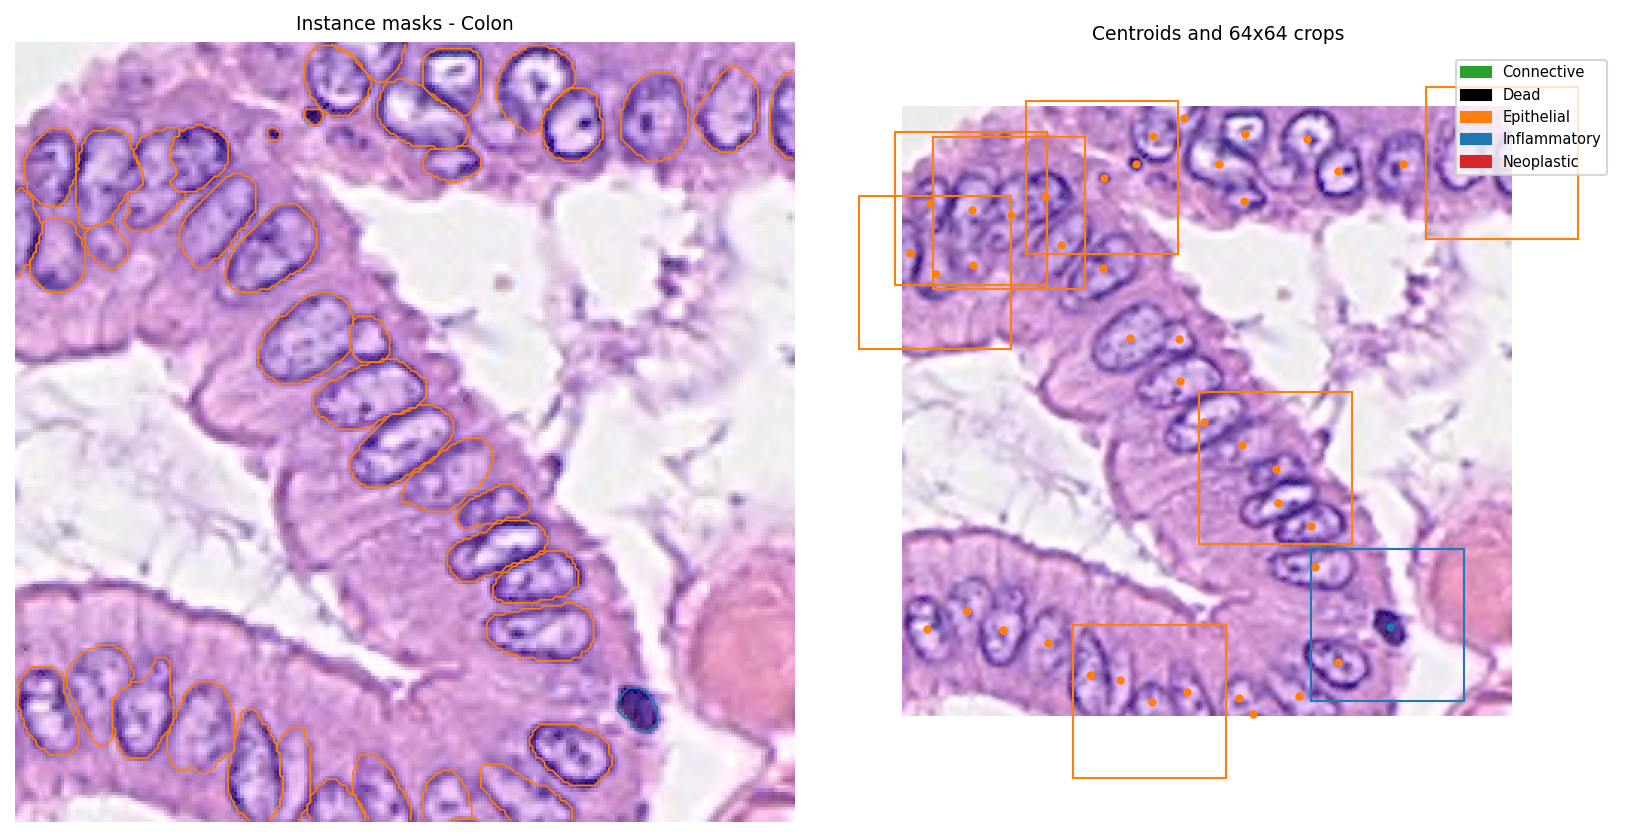

In [13]:
CLASS_COLORS = dict(
    zip(
        CLASSES,
        ["tab:green", "black", "tab:orange", "tab:blue", "tab:red"],
        strict=False,
    )
)
ds0 = hf_folds[TRAIN_FOLDS[0]]
row = ds0[random.Random(SEED).randrange(len(ds0))]  # noqa: S311
img = np.asarray(row["image"].convert("RGB"))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(img)
axes[1].imshow(img)
for j, (inst, cat) in enumerate(zip(row["instances"], row["categories"], strict=False)):
    centroid = nucleus_centroid(np.asarray(inst, dtype=bool))
    if centroid is None:
        continue
    cls = HF_CLASS_NAMES[cat]
    axes[0].contour(
        np.asarray(inst, dtype=float),
        levels=[0.5],
        colors=[CLASS_COLORS[cls]],
        linewidths=0.8,
    )
    axes[1].plot(centroid[1], centroid[0], "o", ms=3, color=CLASS_COLORS[cls])
    if j % 6 == 0:
        axes[1].add_patch(
            mpatches.Rectangle(
                (
                    round(centroid[1]) - CROP_SIZE // 2 - 0.5,
                    round(centroid[0]) - CROP_SIZE // 2 - 0.5,
                ),
                CROP_SIZE,
                CROP_SIZE,
                fill=False,
                ec=CLASS_COLORS[cls],
                lw=1,
            )
        )
axes[0].set_title(f"Instance masks - {HF_TISSUE_NAMES[row['tissue']]}", fontsize=9)
axes[1].set_title(f"Centroids and {CROP_SIZE}x{CROP_SIZE} crops", fontsize=9)
for ax in axes:
    ax.axis("off")
axes[1].legend(
    handles=[mpatches.Patch(color=v, label=k) for k, v in CLASS_COLORS.items()],
    fontsize=7,
    loc="upper right",
)
plt.tight_layout()
plt.show()

### Creating the cell-crop datasets

`PanNukeCellDataset` reads the saved crops of one or more folds and returns the normalised image, the class index and the crop name. We create one dataset each for training, validation and testing.


In [14]:
class PanNukeCellDataset(Dataset):
    """PyTorch dataset of the nucleus-centred PanNuke cell crops."""

    def __init__(
        self,
        root: str | Path,
        folds: list[str],
        transform: transforms.Compose | None = None,
    ) -> None:
        """Collect the crop paths and labels of the given folds."""
        self.transform = transform
        self.classes = CLASSES
        self.class_to_idx = {c: i for i, c in enumerate(CLASSES)}
        self.samples = []
        for fold in folds:
            for cls in CLASSES:
                class_dir = Path(root) / f"{fold}_cell_patches" / cls
                if not class_dir.is_dir():
                    logger.warning("%s does not exist, skipping.", class_dir)
                    continue
                self.samples.extend(
                    (fold, cls, p, self.class_to_idx[cls])
                    for p in sorted(class_dir.iterdir())
                    if p.suffix.lower() in IMG_EXTENSIONS
                )
        if not self.samples:
            msg = f"No images found for folds {folds} under {root}"
            raise RuntimeError(msg)

    def __len__(self) -> int:
        """Number of cell crops."""
        return len(self.samples)

    def __getitem__(self, idx: int) -> tuple:
        """Return (image, label, crop name)."""
        _, _, path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label, path.stem

    def class_counts(self) -> dict[str, int]:
        """Number of crops per class."""
        counts = np.bincount([s[3] for s in self.samples], minlength=len(CLASSES))
        return dict(zip(CLASSES, counts.tolist(), strict=False))


transform = transforms.Compose(
    [
        transforms.Resize((IMG_SIZE, IMG_SIZE)),  # no-op for 64x64 crops
        transforms.ToTensor(),
        transforms.Normalize(mean=NORM_MEAN, std=NORM_STD),
    ]
)

cell_datasets = {
    "train": PanNukeCellDataset(CELL_CROP_ROOT, TRAIN_FOLDS, transform),
    "val": PanNukeCellDataset(CELL_CROP_ROOT, VAL_FOLDS, transform),
    "test": PanNukeCellDataset(CELL_CROP_ROOT, TEST_FOLDS, transform),
}
for split, ds in cell_datasets.items():
    logger.info("%-5s n=%6d  %s", split, len(ds), ds.class_counts())

|2026-11-16|21:30:23.637| [INFO] train n= 62411  {'Connective': 16158, 'Dead': 944, 'Epithelial': 8744, 'Inflammatory': 10678, 'Neoplastic': 25887}
|2026-11-16|21:30:23.644| [INFO] val   n= 59083  {'Connective': 16527, 'Dead': 863, 'Epithelial': 8762, 'Inflammatory': 10488, 'Neoplastic': 22443}
|2026-11-16|21:30:23.650| [INFO] test  n= 65764  {'Connective': 17207, 'Dead': 1036, 'Epithelial': 8724, 'Inflammatory': 10679, 'Neoplastic': 28118}


Below are a few training crops of each class. The green cross marks the centre of the crop, where the nucleus should be.


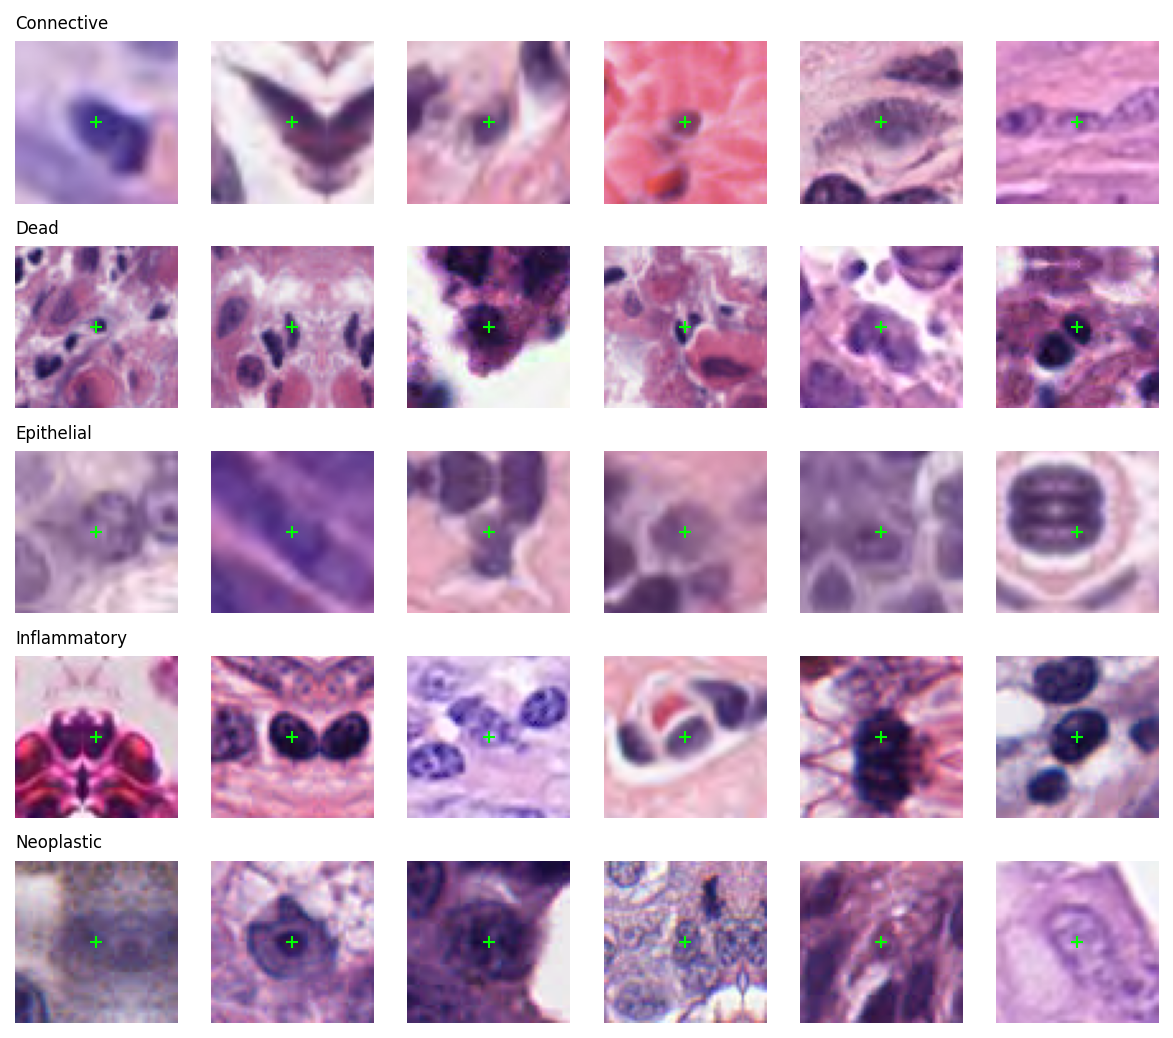

In [15]:
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(8, 7))
ds = cell_datasets["train"]
by_class = {
    i: [j for j, s in enumerate(ds.samples) if s[3] == i] for i in range(len(CLASSES))
}
for i, cls in enumerate(CLASSES):
    picks = random.sample(by_class[i], min(6, len(by_class[i])))
    for j, ax in enumerate(axes[i]):
        ax.axis("off")
        if j < len(picks):
            ax.imshow(Image.open(ds.samples[picks[j]][2]).convert("RGB"))
            ax.plot(CROP_SIZE / 2 - 0.5, CROP_SIZE / 2 - 0.5, "+", color="lime", ms=6)
    axes[i, 0].set_title(cls, fontsize=8, loc="left")
plt.tight_layout()
plt.show()

## Loading the C-LiTE model

### Defining the C-LiTE architecture

The cell below defines the inference-only C-LiTE encoder (ViT-5-S with 4×4 patches). Its building blocks are:

- `RMSNorm`: root-mean-square normalisation, used instead of LayerNorm and for QK-norm inside attention.
- `VisionRotaryEmbedding`: 2D rotary position embeddings (RoPE) for the patch tokens and the register tokens.
- `Attention`: multi-head self-attention with QK-norm, RoPE and optional gating. When `store_attn` is set, it keeps the attention map.
- `Block`: a transformer block with LayerScale (`gamma_1`, `gamma_2`).
- `ViT5`: the full encoder. `forward_features` returns the final CLS token, the patch tokens and the register tokens. Learned position embeddings are interpolated to the input size.


In [16]:
class RMSNorm(nn.Module):
    """Root-mean-square layer normalisation."""

    def __init__(self, dim: int, eps: float = 1e-6) -> None:
        """Initialise the learnable scale."""
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.variance_epsilon = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Normalise the last dimension."""
        dt = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.variance_epsilon)
        return self.weight * x.to(dt)


def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """Map (x0, x1, x2, x3, ...) to (-x1, x0, -x3, x2, ...)."""
    x1, x2 = x.unflatten(-1, (-1, 2)).unbind(-1)
    return torch.stack((-x2, x1), dim=-1).flatten(-2)


def rope_freqs(dim: int, theta: float) -> torch.Tensor:
    """Frequencies of the rotary embedding."""
    return 1.0 / (theta ** (torch.arange(0, dim, 2)[: dim // 2].float() / dim))


class VisionRotaryEmbedding(nn.Module):
    """2D rotary position embedding for a square grid of tokens."""

    def __init__(self, dim: int, pt_seq_len: int, theta: float = 10000) -> None:
        """Initialise the frequencies and an empty cache."""
        super().__init__()
        self.pt_seq_len = pt_seq_len
        self.register_buffer("freqs", rope_freqs(dim, theta))
        self._cache = {}

    def _cos_sin(
        self, n: int, device: torch.device, dtype: torch.dtype
    ) -> tuple[torch.Tensor, torch.Tensor]:
        key = (n, device, dtype)
        if key not in self._cache:
            t = torch.arange(n, device=device) / n * self.pt_seq_len
            f = torch.outer(t, self.freqs.to(device)).repeat_interleave(2, dim=-1)
            f = torch.cat(
                [f[:, None, :].expand(n, n, -1), f[None, :, :].expand(n, n, -1)],
                dim=-1,
            )
            f = f.reshape(n * n, 1, -1)  # (n*n, 1, head_dim)
            self._cache[key] = (f.cos().to(dtype), f.sin().to(dtype))
        return self._cache[key]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Rotate x of shape (B, n*n, heads, head_dim)."""
        n = math.isqrt(x.shape[1])
        cos, sin = self._cos_sin(n, x.device, x.dtype)
        return x * cos + rotate_half(x) * sin


class Attention(nn.Module):
    """Multi-head self-attention with QK-norm, RoPE and optional gating."""

    def __init__(
        self,
        dim: int,
        num_heads: int,
        qkv_bias: bool,  # noqa: FBT001
        rope_pt_seq_len: int,
        rope_reg_size: int,
        num_registers: int,
        reg_theta: float,
        use_rope: bool = True,  # noqa: FBT001, FBT002
        gating_type: str | None = None,
    ) -> None:
        """Initialise the projections, norms and rotary embeddings."""
        super().__init__()
        self.num_heads = num_heads
        head_dim = dim // num_heads
        self.scale = head_dim**-0.5
        self.num_registers = num_registers
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.proj = nn.Linear(dim, dim)
        self.q_norm = RMSNorm(head_dim)
        self.k_norm = RMSNorm(head_dim)
        self.rope = (
            VisionRotaryEmbedding(head_dim // 2, rope_pt_seq_len) if use_rope else None
        )
        self.rope_reg = (
            VisionRotaryEmbedding(head_dim // 2, rope_reg_size, theta=reg_theta)
            if rope_reg_size > 0
            else None
        )
        self.gating_type = gating_type
        if gating_type is not None:
            self.gate_proj = nn.Linear(
                dim, num_heads if gating_type == "headwise" else dim
            )
        self.store_attn, self.last_attn = False, None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Apply self-attention to the token sequence."""
        x_in = x
        b, n, c = x.shape
        r = n - self.num_registers
        q, k, v = (
            self.qkv(x).reshape(b, n, 3, self.num_heads, c // self.num_heads).unbind(2)
        )
        dt = q.dtype
        q, k = self.q_norm(q).to(dt), self.k_norm(k).to(dt)
        if self.rope is not None:  # CLS token is not rotated
            q = torch.cat((q[:, :1], self.rope(q[:, 1:r]), q[:, r:]), dim=1)
            k = torch.cat((k[:, :1], self.rope(k[:, 1:r]), k[:, r:]), dim=1)
        if self.rope_reg is not None:
            q = torch.cat((q[:, :r], self.rope_reg(q[:, r:])), dim=1)
            k = torch.cat((k[:, :r], self.rope_reg(k[:, r:])), dim=1)
        q, k, v = q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2)
        if self.store_attn:
            attn = ((q.float() @ k.float().transpose(-2, -1)) * self.scale).softmax(-1)
            self.last_attn = attn.detach()
            x = attn.to(v.dtype) @ v
        else:
            x = F.scaled_dot_product_attention(q, k, v, scale=self.scale)
        x = x.transpose(1, 2).reshape(b, n, c)
        if self.gating_type is not None:  # gated attention
            g = torch.sigmoid(self.gate_proj(x_in))
            if self.gating_type == "headwise":
                g = (
                    g.unsqueeze(-1)
                    .expand(b, n, self.num_heads, c // self.num_heads)
                    .reshape(b, n, c)
                )
            x = x * g
        return self.proj(x)


class Mlp(nn.Module):
    """Two-layer feed-forward network."""

    def __init__(self, dim: int, hidden: int) -> None:
        """Initialise the two linear layers."""
        super().__init__()
        self.fc1, self.act, self.fc2 = (
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Linear(hidden, dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Apply the MLP."""
        return self.fc2(self.act(self.fc1(x)))


class Block(nn.Module):
    """Transformer block with RMSNorm and LayerScale."""

    def __init__(self, dim: int, mlp_hidden: int, **attn_kw: dict) -> None:
        """Initialise attention, MLP and LayerScale parameters."""
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.attn = Attention(dim, **attn_kw)
        self.norm2 = RMSNorm(dim)
        self.mlp = Mlp(dim, mlp_hidden)
        self.gamma_1 = nn.Parameter(1e-4 * torch.ones(dim))
        self.gamma_2 = nn.Parameter(1e-4 * torch.ones(dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Apply the block."""
        x = x + self.gamma_1 * self.attn(self.norm1(x))
        return x + self.gamma_2 * self.mlp(self.norm2(x))


class PatchEmbed(nn.Module):
    """Split the image into patches and project each patch to a token."""

    def __init__(self, patch_size: int, embed_dim: int, in_chans: int = 3) -> None:
        """Initialise the patch projection."""
        super().__init__()
        self.proj = nn.Conv2d(
            in_chans, embed_dim, kernel_size=patch_size, stride=patch_size
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Return tokens of shape (B, N, embed_dim)."""
        return self.proj(x).flatten(2).transpose(1, 2)


class ViT5(nn.Module):
    """Inference-only C-LiTE encoder. forward() returns the final-norm CLS token."""

    def __init__(  # noqa: PLR0913, PLR0917
        self,
        patch_size: int,
        embed_dim: int,
        depth: int,
        num_heads: int,
        pos_grid: int,
        num_registers: int,
        mlp_hidden: int,
        qkv_bias: bool = False,  # noqa: FBT001, FBT002
        rope_pt_seq_len: int = 14,
        use_rope: bool = True,  # noqa: FBT001, FBT002
        reg_theta: float = 100,
        gating_type: str | None = None,
    ) -> None:
        """Initialise the encoder."""
        super().__init__()
        self.patch_size = patch_size
        self.embed_dim = embed_dim
        self.num_registers = num_registers
        self.patch_embed = PatchEmbed(patch_size, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.reg_token = (
            nn.Parameter(torch.zeros(1, num_registers, embed_dim))
            if num_registers
            else None
        )
        self.pos_embed = nn.Parameter(torch.zeros(1, pos_grid * pos_grid, embed_dim))
        # Unused at inference, kept so that the checkpoint loads without errors.
        self.mask_token = nn.Parameter(torch.zeros(1, embed_dim))
        rope_reg_size = math.isqrt(num_registers)
        if rope_reg_size**2 != num_registers:
            msg = "num_registers must be a square number"
            raise ValueError(msg)
        self.blocks = nn.ModuleList(
            [
                Block(
                    embed_dim,
                    mlp_hidden,
                    num_heads=num_heads,
                    qkv_bias=qkv_bias,
                    rope_pt_seq_len=rope_pt_seq_len,
                    rope_reg_size=rope_reg_size,
                    num_registers=num_registers,
                    reg_theta=reg_theta,
                    use_rope=use_rope,
                    gating_type=gating_type,
                )
                for _ in range(depth)
            ]
        )
        self.norm = RMSNorm(embed_dim)

    def interpolate_pos_encoding(self, n_patch: int, h: int, w: int) -> torch.Tensor:
        """Resize the learned position embeddings to the input grid."""
        n, dim = self.pos_embed.shape[1:]
        if n_patch == n and w == h:
            return self.pos_embed
        g = math.isqrt(n)
        pe = self.pos_embed.reshape(1, g, g, dim).permute(0, 3, 1, 2)
        pe = F.interpolate(
            pe.float(),
            size=(h // self.patch_size, w // self.patch_size),
            mode="bicubic",
            align_corners=False,
        ).to(self.pos_embed.dtype)
        return pe.permute(0, 2, 3, 1).reshape(1, -1, dim)

    def forward_features(self, x: torch.Tensor) -> dict[str, torch.Tensor]:
        """Return the final CLS, patch and register tokens."""
        b, _, h, w = x.shape
        x = self.patch_embed(x)
        x = x + self.interpolate_pos_encoding(x.shape[1], h, w)
        x = torch.cat((self.cls_token.expand(b, -1, -1), x), dim=1)
        if self.reg_token is not None:
            x = torch.cat((x, self.reg_token.expand(b, -1, -1)), dim=1)
        for blk in self.blocks:
            x = blk(x)
        x = self.norm(x)
        r = self.num_registers
        return {
            "cls": x[:, 0],
            "patch": x[:, 1 : x.shape[1] - r],
            "reg": x[:, x.shape[1] - r :],
        }

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Return the CLS token."""
        return self.forward_features(x)["cls"]

### Loading the pretrained weights

The checkpoint is saved during self-supervised training, so it may contain the teacher, the student and the projection heads. `normalize_state_dict` keeps only the backbone weights, preferring the teacher, and strips the training prefixes. `build_vit5_from_state_dict` then reads the architecture (embedding size, depth, heads, patch size, registers) directly from the weights.

The weights must load with no missing and no unexpected keys. The only exception is the RoPE frequencies, which are recomputed.


In [17]:
def normalize_state_dict(sd: dict) -> dict:
    """Extract the backbone weights from a C-LiTE training checkpoint."""
    for key in ("model", "state_dict"):
        if isinstance(sd, dict) and isinstance(sd.get(key), dict):
            sd = sd[key]
    if isinstance(sd.get("teacher"), dict):
        sd = sd["teacher"]
    elif isinstance(sd.get("student"), dict):
        logger.info("No 'teacher' key -- using the 'student' weights.")
        sd = sd["student"]
    for pref in ("teacher.backbone.", "student.backbone.", "backbone.", "module."):
        hits = {
            k[len(pref) :].replace("_fsdp_wrapped_module.", ""): v
            for k, v in sd.items()
            if k.startswith(pref)
        }
        if hits:
            logger.info("Stripped prefix '%s' -> %d tensors", pref, len(hits))
            sd = hits
            break
    heads = ("dino_head", "ibot_head", "gram_teacher", "contrastive_head", "head.")
    return {k: v for k, v in sd.items() if not k.startswith(heads)}


def build_vit5_from_state_dict(sd: dict) -> tuple[ViT5, dict]:
    """Infer the encoder configuration from the weights and build the model."""
    embed_dim = sd["cls_token"].shape[-1]
    depth = 1 + max(int(k.split(".")[1]) for k in sd if k.startswith("blocks."))
    head_dim = sd["blocks.0.attn.q_norm.weight"].shape[0]
    num_heads = embed_dim // head_dim
    gate_key = "blocks.0.attn.gate_proj.weight"
    if gate_key not in sd:
        gating_type = None
    elif sd[gate_key].shape[0] == num_heads:
        gating_type = "headwise"
    else:
        gating_type = "elementwise"
    cfg = {
        "patch_size": sd["patch_embed.proj.weight"].shape[-1],
        "embed_dim": embed_dim,
        "depth": depth,
        "num_heads": num_heads,
        "pos_grid": math.isqrt(sd["pos_embed"].shape[1]),
        "num_registers": sd["reg_token"].shape[1] if "reg_token" in sd else 0,
        "mlp_hidden": sd["blocks.0.mlp.fc1.weight"].shape[0],
        "qkv_bias": "blocks.0.attn.qkv.bias" in sd,
        "rope_pt_seq_len": ROPE_PT_SEQ_LEN,
        "use_rope": True,
        "reg_theta": REG_THETA,
        "gating_type": gating_type,
    }
    if cfg["pos_grid"] ** 2 != sd["pos_embed"].shape[1]:
        msg = "pos_embed grid must be square"
        raise ValueError(msg)
    return ViT5(**cfg), cfg


ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
state_dict = normalize_state_dict(ckpt)
del ckpt

model, arch = build_vit5_from_state_dict(state_dict)
logger.info("Architecture: %s", arch)
if EXPECTED_PATCH_SIZE is not None and arch["patch_size"] != EXPECTED_PATCH_SIZE:
    msg = f"Checkpoint patch size is {arch['patch_size']}, not {EXPECTED_PATCH_SIZE}"
    raise ValueError(msg)

missing, unexpected = model.load_state_dict(state_dict, strict=False)
missing_ok = [
    k for k in missing if k.endswith(("attn.rope.freqs", "attn.rope_reg.freqs"))
]
missing = [k for k in missing if k not in missing_ok]
logger.info(
    "Missing keys (%d): %s (+%d RoPE freqs recomputed)",
    len(missing),
    missing,
    len(missing_ok),
)
logger.info("Unexpected keys (%d): %s", len(unexpected), unexpected)
if missing or unexpected:
    msg = "Checkpoint does not match the ViT-5 architecture"
    raise RuntimeError(msg)

model = model.to(device).eval()
g_in = IMG_SIZE // arch["patch_size"]
logger.info(
    "Backbone params: %.1fM | input %dpx -> %dx%d patch tokens (+1 CLS, +%d reg)",
    sum(p.numel() for p in model.parameters()) / 1e6,
    IMG_SIZE,
    g_in,
    g_in,
    arch["num_registers"],
)

|2026-11-16|21:30:52.603| [INFO] Stripped prefix 'backbone.' -> 187 tensors
|2026-11-16|21:30:52.925| [INFO] Architecture: {'patch_size': 4, 'embed_dim': 384, 'depth': 12, 'num_heads': 6, 'pos_grid': 56, 'num_registers': 4, 'mlp_hidden': 1536, 'qkv_bias': False, 'rope_pt_seq_len': 14, 'use_rope': True, 'reg_theta': 100, 'gating_type': None}
|2026-11-16|21:30:52.954| [INFO] Missing keys (0): [] (+0 RoPE freqs recomputed)
|2026-11-16|21:30:52.955| [INFO] Unexpected keys (0): []
|2026-11-16|21:30:53.239| [INFO] Backbone params: 22.5M | input 64px -> 16x16 patch tokens (+1 CLS, +4 reg)


## Extracting C-LiTE features

The encoder stays frozen. We pass every crop through C-LiTE and keep the final CLS token, or the CLS token together with the mean patch token if `FEATURE_MODE = "cls+patchmean"`. Mixed precision is used on GPU to speed this up.

The features of each split are saved to a compressed `.npz` file in `OUTPUT_DIR`. If a cached file with the right number of rows exists, it is loaded instead of extracting again.


In [19]:
import gc

_amp_dtype = getattr(torch, AMP_DTYPE)


def embed(model: ViT5, imgs: torch.Tensor) -> torch.Tensor:
    """Return the feature vector of each image according to FEATURE_MODE."""
    out = model.forward_features(imgs)
    if FEATURE_MODE == "cls":
        return out["cls"]
    if FEATURE_MODE == "cls+patchmean":
        return torch.cat([out["cls"], out["patch"].mean(1)], dim=-1)
    raise ValueError(FEATURE_MODE)


@torch.no_grad()
def extract_features(
    model: ViT5, dataset: Dataset, desc: str
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Extract features, labels and crop names for a whole dataset."""
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=device.type == "cuda",
    )
    feats, labels, ids = [], [], []
    for batch, y, uid in tqdm(loader, desc=desc):
        imgs = batch.to(device, non_blocking=True)
        with torch.autocast(
            device_type=device.type,
            dtype=_amp_dtype,
            enabled=USE_AMP and device.type == "cuda",
        ):
            f = embed(model, imgs)
        feats.append(f.float().cpu().numpy())
        labels.append(y.numpy())
        ids.extend(uid)
    # Shut down this loader's worker processes now. Otherwise the workers that
    # the next DataLoader forks can inherit it and print a harmless
    # "can only test a child process" error when they clean up.
    del loader
    gc.collect()
    return np.concatenate(feats), np.concatenate(labels), np.array(ids)


features = {}
for split, ds in cell_datasets.items():
    cache = (
        OUTPUT_DIR
        / f"{MODEL_TAG}_{FEATURE_MODE.replace('+', '_')}_{split}_features.npz"
    )
    if CACHE_FEATURES and cache.exists():
        d = np.load(cache, allow_pickle=False)
        if len(d["labels"]) == len(ds):
            features[split] = (d["features"], d["labels"], d["ids"])
            logger.info(
                "Loaded cached %s features %s from %s",
                split,
                d["features"].shape,
                cache,
            )
            continue
        logger.info(
            "Cache %s has %d rows but dataset has %d -- re-extracting",
            cache,
            len(d["labels"]),
            len(ds),
        )
    t0 = time.time()
    x_split, y_split, ids_split = extract_features(model, ds, f"Extracting {split}")
    np.savez_compressed(cache, features=x_split, labels=y_split, ids=ids_split)
    features[split] = (x_split, y_split, ids_split)
    logger.info("%s: %s in %.0fs -> %s", split, x_split.shape, time.time() - t0, cache)

X_train, y_train, _ = features["train"]
X_val, y_val, _ = features["val"]
X_test, y_test, _ = features["test"]

|2026-11-16|21:47:46.225| [INFO] Loaded cached train features (62411, 384) from tmp/clite/vit5_pi_pannuke_results/vit5_pi_cls_train_features.npz
|2026-11-16|21:47:48.774| [INFO] Loaded cached val features (59083, 384) from tmp/clite/vit5_pi_pannuke_results/vit5_pi_cls_val_features.npz
|2026-11-16|21:47:52.788| [INFO] Loaded cached test features (65764, 384) from tmp/clite/vit5_pi_pannuke_results/vit5_pi_cls_test_features.npz


## Linear-probe evaluation

### Defining the evaluation metrics

PanNuke is imbalanced: there are far fewer *Dead* cells than *Neoplastic* or *Inflammatory* ones. We therefore report balanced accuracy, macro-averaged F1, precision and recall, and Cohen's kappa, as well as plain accuracy. When class probabilities are available, we also report the macro AUROC, mean average precision (mAP) and log loss, plus the F1 score of each class.


In [20]:
def compute_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    proba: np.ndarray | None,
    n_classes: int = len(CLASSES),
) -> dict[str, float]:
    """Compute the classification metrics used in this notebook."""
    m = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced_Acc": balanced_accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted_F1": f1_score(y_true, y_pred, average="weighted"),
        "Macro_Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Cohen_Kappa": cohen_kappa_score(y_true, y_pred),
    }
    if proba is not None:
        y_bin = label_binarize(y_true, classes=list(range(n_classes)))
        m["AUROC"] = roc_auc_score(y_bin, proba, average="macro", multi_class="ovr")
        m["mAP"] = average_precision_score(y_bin, proba, average="macro")
        m["LogLoss"] = log_loss(y_true, proba, labels=list(range(n_classes)))
    per_class = f1_score(y_true, y_pred, average=None, labels=list(range(n_classes)))
    for c, f in zip(CLASSES, per_class, strict=False):
        m[f"F1_{c}"] = f
    return m


def report(
    name: str, y_true: np.ndarray, y_pred: np.ndarray, proba: np.ndarray | None
) -> dict[str, float]:
    """Log the metrics and the classification report of one evaluation."""
    m = compute_metrics(y_true, y_pred, proba)
    lines = [f"=== {name} ==="] + [f"  {k:18s} {v:.4f}" for k, v in m.items()]
    logger.info("\n%s", "\n".join(lines))
    logger.info(
        "\n%s",
        classification_report(
            y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0
        ),
    )
    return m

### Training the linear probe

We train a multinomial logistic-regression classifier on the frozen Fold1 features. The L2 penalty is set to `100 / (M × C)`, where `M` is the feature dimension and `C` the number of classes. We then evaluate the probe on Fold2 (validation) and Fold3 (test).


In [21]:
M, C = X_train.shape[1], len(np.unique(y_train))
l2 = 100 / (M * C)
logger.info("features=%d, classes=%d, l2=%.5f, C=%.2f", M, C, l2, 1 / l2)

t0 = time.time()
logreg = LogisticRegression(C=1 / l2, max_iter=LOGREG_MAX_ITER, solver="lbfgs")
logreg.fit(X_train, y_train)
logger.info("Fit in %.0fs", time.time() - t0)

results = {
    "logreg_val": report(
        "LogReg | val (Fold2)",
        y_val,
        logreg.predict(X_val),
        logreg.predict_proba(X_val),
    ),
    "logreg_test": report(
        "LogReg | test (Fold3)",
        y_test,
        logreg.predict(X_test),
        logreg.predict_proba(X_test),
    ),
}

|2026-11-16|21:49:08.987| [INFO] features=384, classes=5, l2=0.05208, C=19.20
|2026-11-16|21:50:17.107| [INFO] Fit in 68s
|2026-11-16|21:50:18.026| [INFO] 
=== LogReg | val (Fold2) ===
  Accuracy           0.7565
  Balanced_Acc       0.7041
  Macro_F1           0.7094
  Weighted_F1        0.7547
  Macro_Precision    0.7168
  Macro_Recall       0.7041
  Cohen_Kappa        0.6610
  AUROC              0.9321
  mAP                0.7685
  LogLoss            0.6629
  F1_Connective      0.7249
  F1_Dead            0.5804
  F1_Epithelial      0.6854
  F1_Inflammatory    0.7377
  F1_Neoplastic      0.8184
|2026-11-16|21:50:18.059| [INFO] 
              precision    recall  f1-score   support

  Connective     0.7377    0.7126    0.7249     16527
        Dead     0.5814    0.5794    0.5804       863
  Epithelial     0.7428    0.6363    0.6854      8762
Inflammatory     0.7316    0.7439    0.7377     10488
  Neoplastic     0.7904    0.8484    0.8184     22443

    accuracy                       

### Summarizing the results

The table below puts the validation and test metrics side by side. The same numbers are saved to a CSV file in `OUTPUT_DIR`.


In [22]:
keys = list(results["logreg_test"].keys())
lines = [f"{'metric':18s}" + "".join(f"{r:>14s}" for r in results)]
lines += [
    f"{k:18s}" + "".join(f"{results[r].get(k, float('nan')):14.4f}" for r in results)
    for k in keys
]
logger.info("\n%s", "\n".join(lines))

out_csv = (
    OUTPUT_DIR / f"{MODEL_TAG}_{FEATURE_MODE.replace('+', '_')}_pannuke_metrics.csv"
)
with out_csv.open("w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["run", *keys])
    for r, m in results.items():
        writer.writerow([r] + [m.get(k, "") for k in keys])
logger.info("Saved %s", out_csv)

|2026-11-16|21:50:50.095| [INFO] 
metric                logreg_val   logreg_test
Accuracy                  0.7565        0.7598
Balanced_Acc              0.7041        0.6891
Macro_F1                  0.7094        0.7024
Weighted_F1               0.7547        0.7574
Macro_Precision           0.7168        0.7190
Macro_Recall              0.7041        0.6891
Cohen_Kappa               0.6610        0.6553
AUROC                     0.9321        0.9333
mAP                       0.7685        0.7665
LogLoss                   0.6629        0.6465
F1_Connective             0.7249        0.7151
F1_Dead                   0.5804        0.5800
F1_Epithelial             0.6854        0.6595
F1_Inflammatory           0.7377        0.7249
F1_Neoplastic             0.8184        0.8325
|2026-11-16|21:50:50.097| [INFO] Saved tmp/clite/vit5_pi_pannuke_results/vit5_pi_cls_pannuke_metrics.csv


The row-normalised confusion matrix on the test fold shows which classes the linear probe confuses. Each row sums to 1, so the diagonal gives the recall of each class.


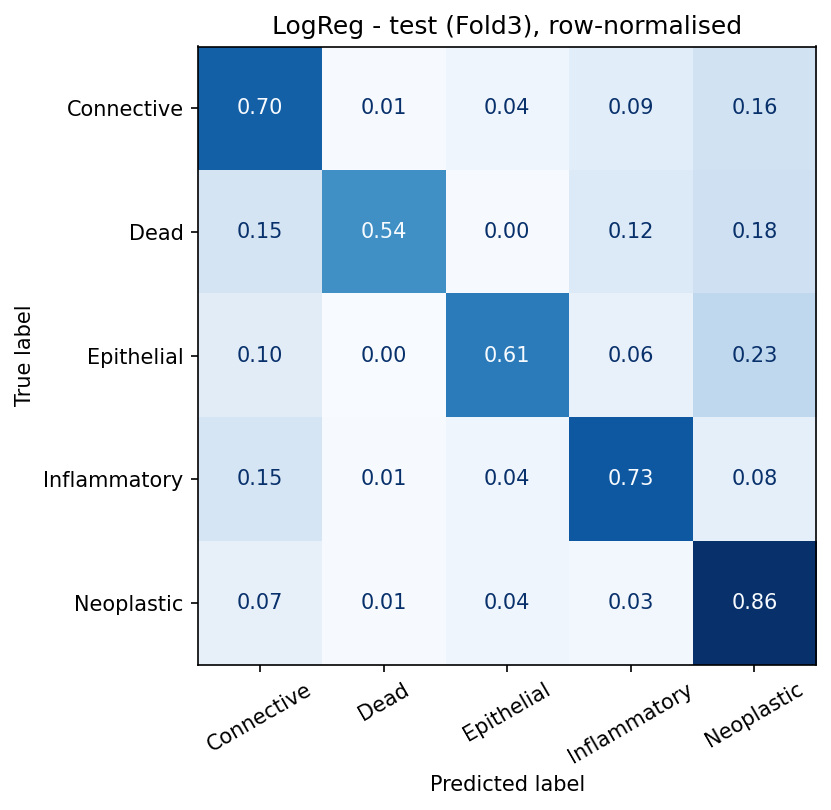

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
cm = confusion_matrix(
    y_test,
    logreg.predict(X_test),
    normalize="true",
    labels=list(range(len(CLASSES))),
)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False
)
ax.set_title("LogReg - test (Fold3), row-normalised")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## Visualizing C-LiTE features

In this section, we look at what C-LiTE encodes, first inside a single cell (patch tokens) and then across the test fold (CLS features).

### Selecting example cells

By default we pick one random test crop of each class. To inspect your own crops, set `VIS_PATHS` to a list of image paths.


In [24]:
VIS_PATHS = None  # or a list of crop paths, e.g. ["path/to/crop.png", ...]

VIS_DIR = OUTPUT_DIR / "visualizations"
PCA_DIR = VIS_DIR / "pca"
PCA_DIR.mkdir(parents=True, exist_ok=True)

if VIS_PATHS is None:
    rng = random.Random(SEED)  # noqa: S311
    test_ds = cell_datasets["test"]
    VIS_PATHS = [
        rng.choice([s[2] for s in test_ds.samples if s[1] == c])
        for c in CLASSES
        if any(s[1] == c for s in test_ds.samples)
    ]
VIS_PATHS = [Path(p) for p in VIS_PATHS]


def short_label(p: str | Path) -> str:
    """Return the class name from a crop file name."""
    n = Path(p).stem
    return n.split("_")[3] if n.count("_") >= 3 else n  # noqa: PLR2004


logger.info("Example cells:\n%s", "\n".join(str(p) for p in VIS_PATHS))

|2026-11-16|21:51:07.669| [INFO] Example cells:
tmp/clite/pannuke_cell_crops/Fold3_cell_patches/Connective/fold3_00764_00021_Connective_Colon.png
tmp/clite/pannuke_cell_crops/Fold3_cell_patches/Dead/fold3_00930_00091_Dead_Lung.png
tmp/clite/pannuke_cell_crops/Fold3_cell_patches/Epithelial/fold3_01021_00027_Epithelial_Skin.png
tmp/clite/pannuke_cell_crops/Fold3_cell_patches/Inflammatory/fold3_01008_00002_Inflammatory_Thyroid.png
tmp/clite/pannuke_cell_crops/Fold3_cell_patches/Neoplastic/fold3_00879_00010_Neoplastic_Prostate.png


### PCA of patch tokens

Each 64×64 crop gives a 16×16 grid of patch tokens. For each cell, we reduce its patch tokens to 3 principal components and show them as RGB colours, upsampled to the size of the crop. Patches with similar colours have similar features. The nucleus, the cytoplasm and the background should therefore appear as separate regions.


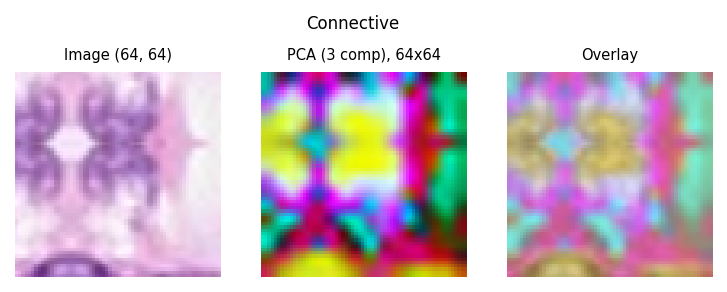

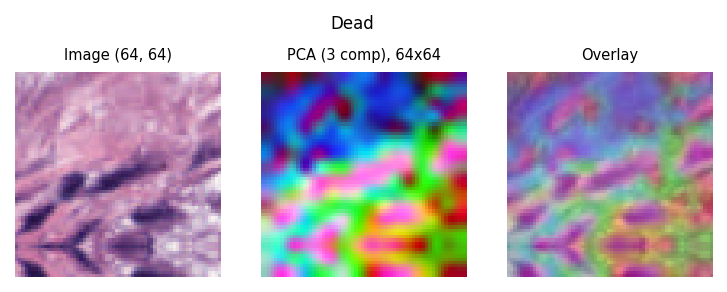

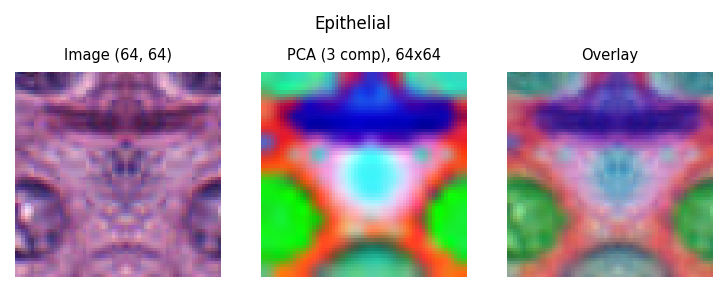

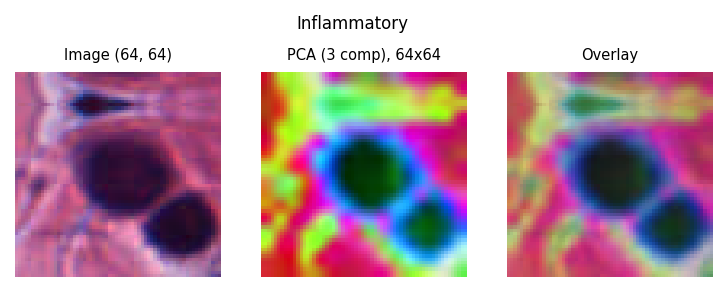

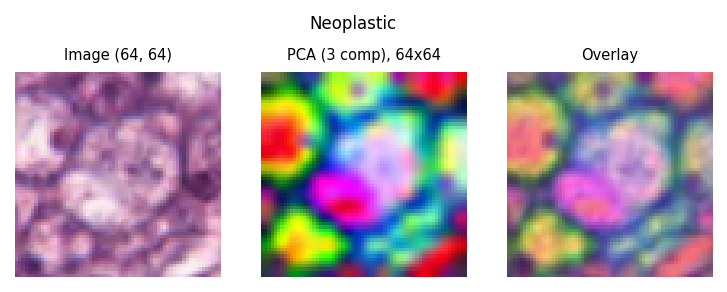

|2026-11-16|21:51:32.960| [INFO] Saved 5 PCA figures to tmp/clite/vit5_pi_pannuke_results/visualizations/pca


In [25]:
def resize_transform(
    img: Image.Image, image_size: int = IMG_SIZE, patch_size: int | None = None
) -> torch.Tensor:
    """Resize to a square multiple of the patch size; returns (3,H,W) in [0, 1]."""
    patch_size = patch_size or model.patch_size
    h_p = int(image_size / patch_size)
    return TF.to_tensor(TF.resize(img, (h_p * patch_size, h_p * patch_size)))


@torch.no_grad()
def patch_tokens(model: ViT5, img_norm: torch.Tensor) -> torch.Tensor:
    """Return the final-norm patch tokens of one normalised image (3,H,W)."""
    out = model.forward_features(img_norm.unsqueeze(0).to(device))
    return out["patch"][0].float().cpu()


def pca_rgb(
    proj: np.ndarray, h_p: int, w_p: int, out_hw: tuple[int, int]
) -> np.ndarray:
    """Map 3 PCA components to RGB and upsample to the image size."""
    t = (
        torch.sigmoid(torch.as_tensor(proj, dtype=torch.float32).mul(2.0))
        .view(h_p, w_p, 3)
        .permute(2, 0, 1)
    )
    t = F.interpolate(t.unsqueeze(0), size=out_hw, mode="bicubic", align_corners=False)
    return t.squeeze(0).clamp(0, 1).permute(1, 2, 0).numpy()


pca_items = []  # (path, resized image, tokens, h_p, w_p), reused by the joint PCA
for p in VIS_PATHS:
    image = Image.open(p).convert("RGB")
    img_r = resize_transform(image)
    x = patch_tokens(model, TF.normalize(img_r, mean=NORM_MEAN, std=NORM_STD))
    h_p, w_p = (d // model.patch_size for d in img_r.shape[1:])
    pca_items.append((p, img_r, x, h_p, w_p))

    proj = PCA(n_components=3, whiten=True).fit_transform(x.numpy())
    img_h, img_w = img_r.shape[1:]
    pca_up = pca_rgb(proj, h_p, w_p, (img_h, img_w))
    img_np = img_r.permute(1, 2, 0).numpy()

    fig, axes = plt.subplots(1, 3, figsize=(6, 2.2))
    panels = [
        (image, f"Image {image.size}"),
        (pca_up, f"PCA (3 comp), {img_h}x{img_w}"),
        (0.5 * img_np + 0.5 * pca_up, "Overlay"),
    ]
    for ax, (pnl, title) in zip(axes, panels, strict=False):
        ax.imshow(pnl)
        ax.set_title(title, fontsize=7)
        ax.axis("off")
    fig.suptitle(short_label(p), fontsize=8)
    fig.savefig(PCA_DIR / f"pca_{p.stem}.png", bbox_inches="tight", dpi=300)
    plt.show()
logger.info("Saved %d PCA figures to %s", len(VIS_PATHS), PCA_DIR)

### t-SNE and UMAP of CLS features

Finally, we project the CLS features of the test fold to 2D with t-SNE and UMAP. The top row colours each cell by its class and the bottom row by its tissue type. Well-separated class clusters show that the cell types can be told apart from the frozen features alone, without fine-tuning.

t-SNE is slow on many points, so we use a stratified subsample of at most `EMB_MAX_POINTS` cells. Rare classes listed in `EMB_KEEP_ALL` are always kept in full. The features are L2-normalised and reduced to `EMB_PCA_DIMS` dimensions with PCA before t-SNE and UMAP.


|2026-11-16|21:52:07.782| [INFO] test: using 20000 / 65764 cells -> {'Connective': 5041, 'Dead': 1036, 'Epithelial': 2556, 'Inflammatory': 3129, 'Neoplastic': 8238}
|2026-11-16|21:56:18.064| [INFO] t-SNE done in 250s
|2026-11-16|21:57:30.296| [INFO] UMAP done in 72s


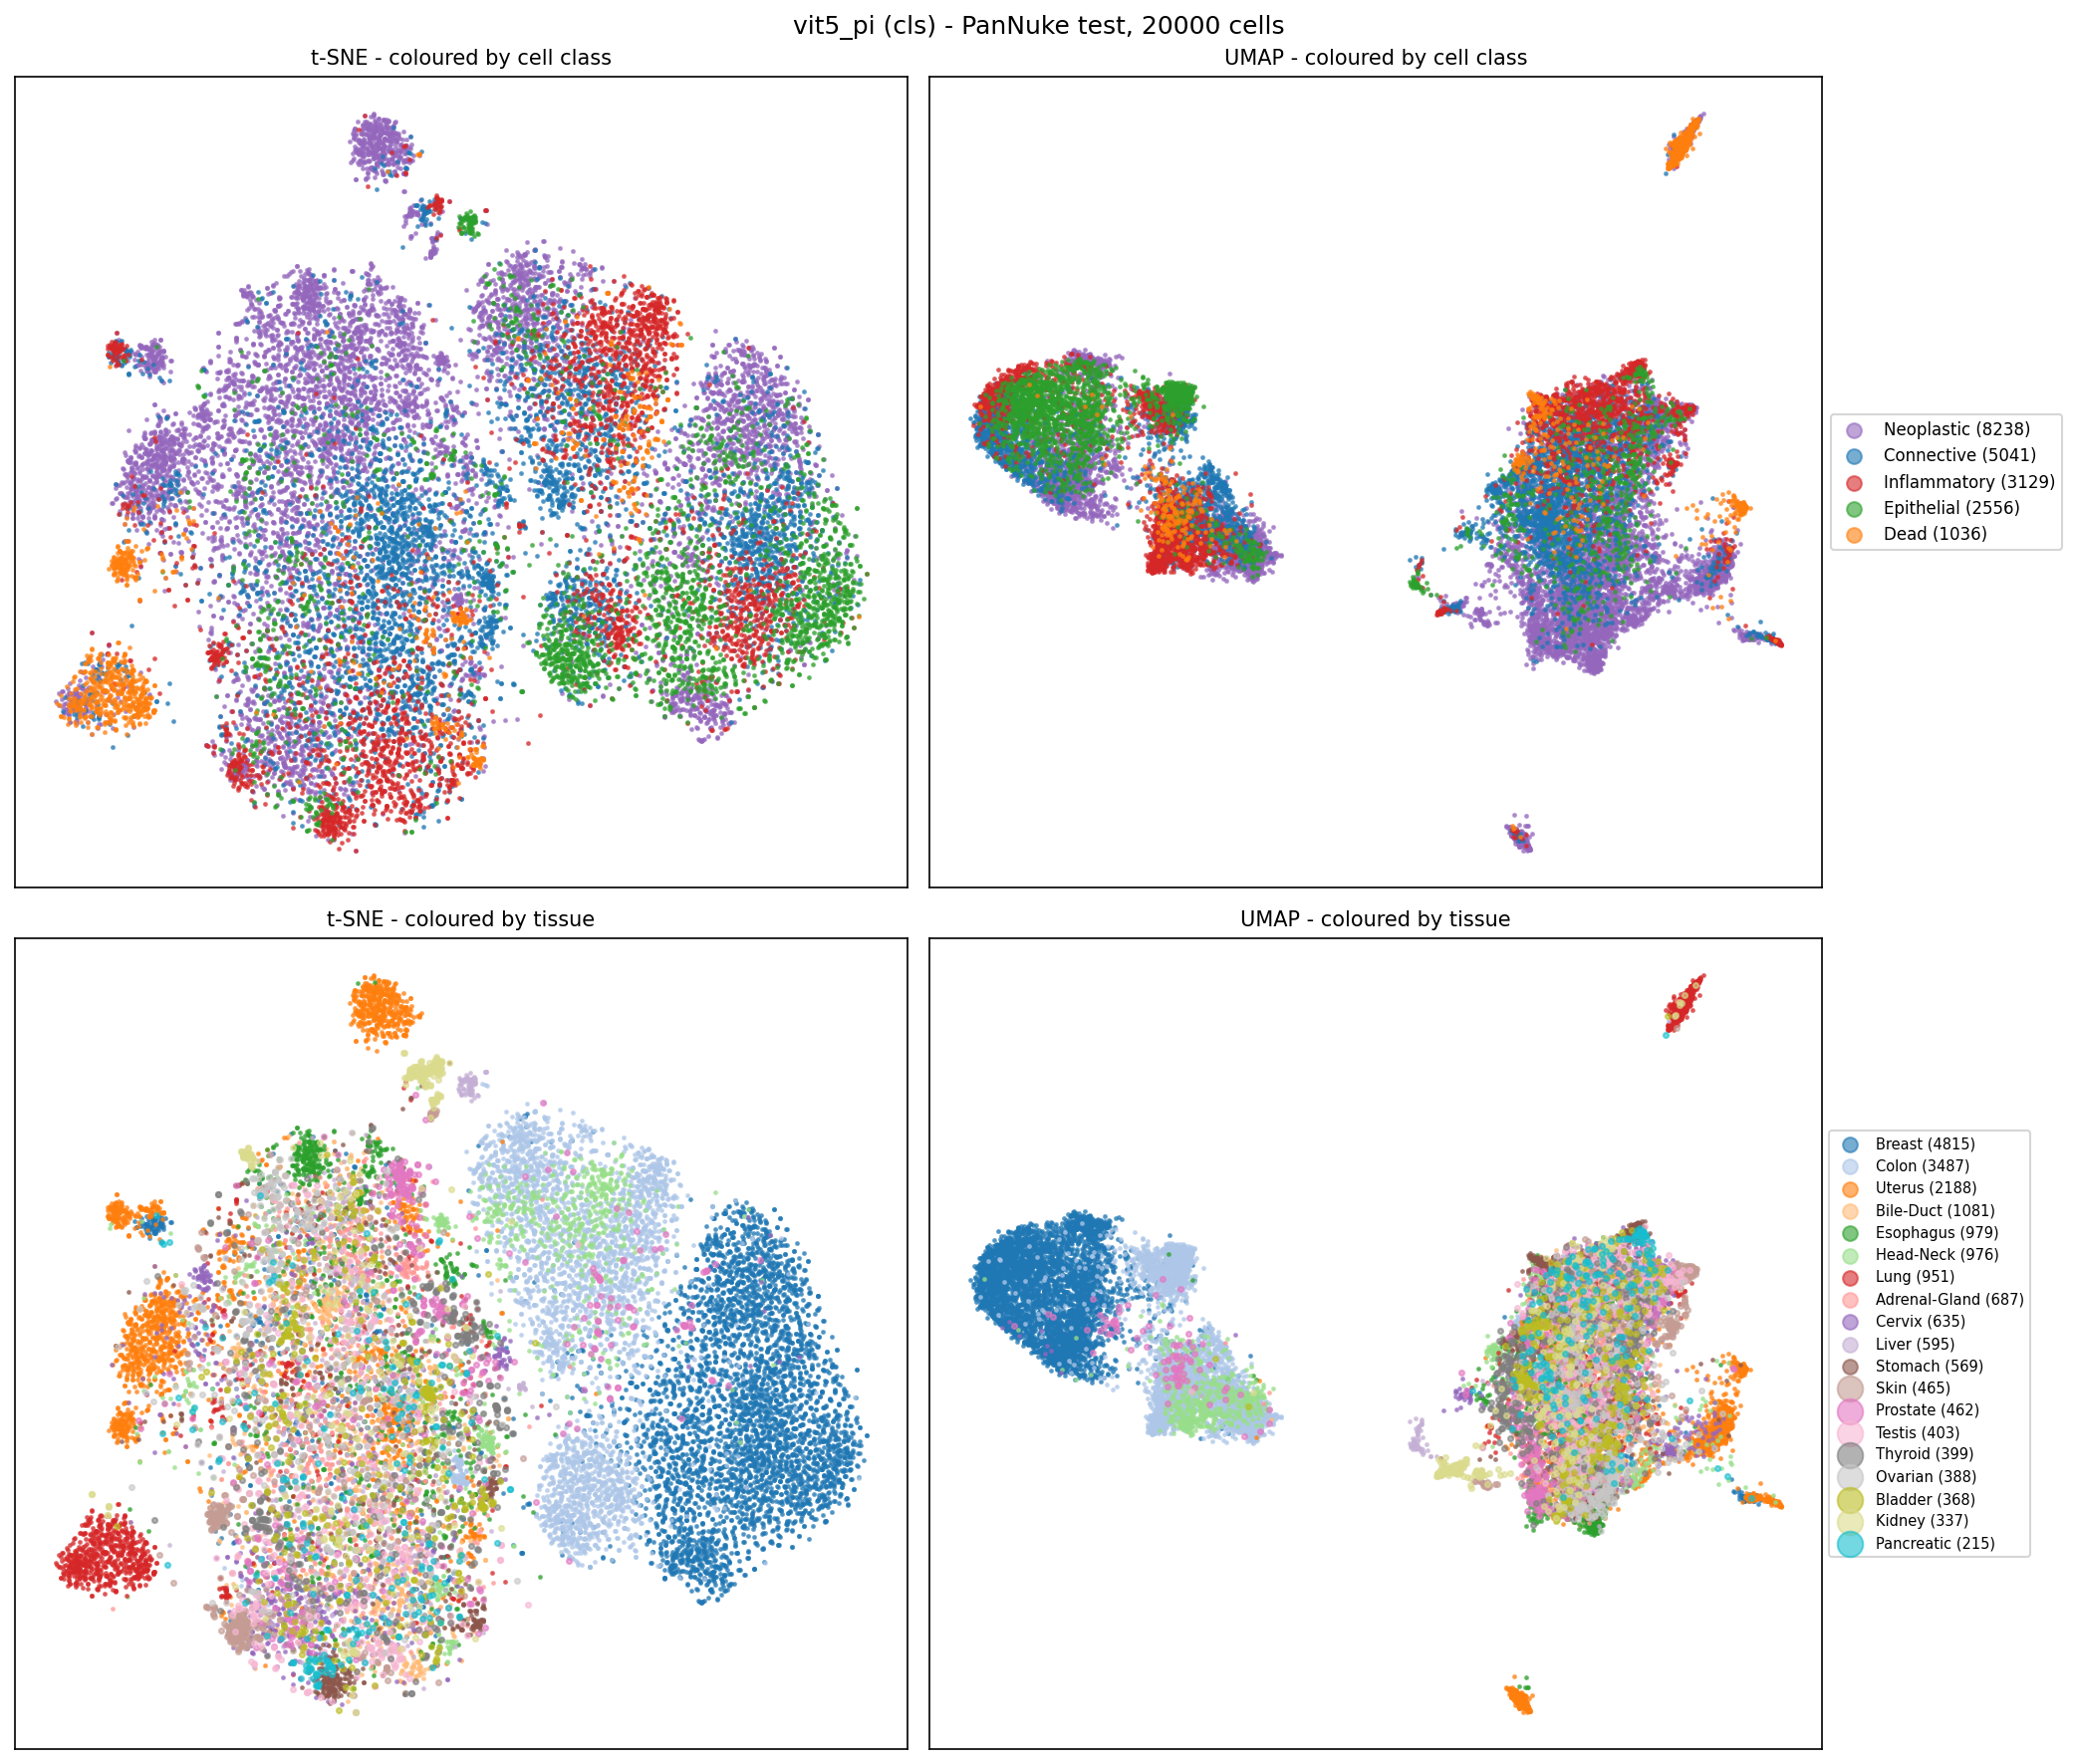

|2026-11-16|21:57:33.348| [INFO] Saved tmp/clite/vit5_pi_pannuke_results/visualizations/embeddings/tsne_umap_test.png


In [27]:
EMB_SPLIT = "test"  # "train", "val" or "test"
EMB_MAX_POINTS = 20000
EMB_KEEP_ALL = ["Dead"]  # classes that are never subsampled
EMB_PCA_DIMS = 50
TSNE_PERPLEXITY = 30
UMAP_NEIGHBORS = 30
UMAP_MIN_DIST = 0.1

X_all, y_all, ids_all = features[EMB_SPLIT]

# Stratified subsample: every class shrinks by the same factor,
# EMB_KEEP_ALL classes are kept whole.
rng = np.random.default_rng(SEED)
keep_ids = [CLASSES.index(c) for c in EMB_KEEP_ALL if c in CLASSES]
always = np.flatnonzero(np.isin(y_all, keep_ids))
rest = np.flatnonzero(~np.isin(y_all, keep_ids))
budget = max(EMB_MAX_POINTS - len(always), 0)
if len(rest) > budget:
    frac = budget / len(rest)
    rest = np.concatenate(
        [
            rng.choice(idx, max(1, round(len(idx) * frac)), replace=False)
            for c in np.unique(y_all[rest])
            for idx in [rest[y_all[rest] == c]]
        ]
    )
sel = np.sort(np.concatenate([always, rest]))
X_emb, y_emb, ids_emb = X_all[sel], y_all[sel], ids_all[sel]
tissue = np.array([s.split("_")[4] if s.count("_") >= 4 else "?" for s in ids_emb])  # noqa: PLR2004
logger.info(
    "%s: using %d / %d cells -> %s",
    EMB_SPLIT,
    len(sel),
    len(y_all),
    {c: int((y_emb == i).sum()) for i, c in enumerate(CLASSES)},
)

# L2-normalise, then PCA
Xn = X_emb / (np.linalg.norm(X_emb, axis=1, keepdims=True) + 1e-12)
Xp = PCA(
    n_components=min(EMB_PCA_DIMS, Xn.shape[1], len(Xn) - 1), random_state=SEED
).fit_transform(Xn)

t0 = time.time()
emb = {
    "t-SNE": TSNE(
        n_components=2,
        perplexity=min(TSNE_PERPLEXITY, (len(Xp) - 1) / 3),
        init="pca",
        learning_rate="auto",
        random_state=SEED,
    ).fit_transform(Xp)
}
logger.info("t-SNE done in %.0fs", time.time() - t0)
t0 = time.time()
emb["UMAP"] = umap.UMAP(
    n_neighbors=min(UMAP_NEIGHBORS, len(Xp) - 1),
    min_dist=UMAP_MIN_DIST,
    metric="euclidean",
    random_state=SEED,
).fit_transform(Xp)
logger.info("UMAP done in %.0fs", time.time() - t0)


def scatter(
    ax: plt.Axes,
    z: np.ndarray,
    labels: np.ndarray,
    names: list[str],
    title: str,
    cmap: str = "tab10",
) -> None:
    """Scatter a 2D embedding coloured by label, largest groups drawn first."""
    max_tab10 = 10
    colors = plt.get_cmap(cmap if len(names) <= max_tab10 else "tab20")
    order = np.argsort([-(labels == n).sum() for n in names])
    for k in order:
        m = labels == names[k]
        ax.scatter(
            z[m, 0],
            z[m, 1],
            s=2 if m.sum() > 500 else 6,  # noqa: PLR2004
            alpha=0.6,
            color=colors(k % colors.N),
            label=f"{names[k]} ({m.sum()})",
            rasterized=True,
        )
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])


class_names = np.array(CLASSES)[y_emb]
tissues = sorted(set(tissue), key=lambda t: -(tissue == t).sum())
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for col, (name, z) in enumerate(emb.items()):
    scatter(axes[0, col], z, class_names, CLASSES, f"{name} - coloured by cell class")
    scatter(axes[1, col], z, tissue, tissues, f"{name} - coloured by tissue")
axes[0, 1].legend(markerscale=5, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
axes[1, 1].legend(markerscale=5, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
fig.suptitle(
    f"{MODEL_TAG} ({FEATURE_MODE}) - PanNuke {EMB_SPLIT}, {len(sel)} cells",
    fontsize=12,
)
plt.tight_layout()
emb_dir = VIS_DIR / "embeddings"
emb_dir.mkdir(parents=True, exist_ok=True)
out = emb_dir / f"tsne_umap_{EMB_SPLIT}.png"
plt.savefig(out, dpi=200, bbox_inches="tight")
plt.show()
np.savez_compressed(
    emb_dir / f"tsne_umap_{EMB_SPLIT}.npz",
    tsne=emb["t-SNE"],
    umap=emb["UMAP"],
    labels=y_emb,
    ids=ids_emb,
)
logger.info("Saved %s", out)

## Summary

In this notebook, we:

1. turned the PanNuke folds into nucleus-centred 64×64 cell crops,
2. loaded the C-LiTE encoder from its self-supervised training checkpoint,
3. extracted frozen CLS features for every cell,
4. trained a logistic-regression linear probe on Fold1 and evaluated it on Fold2 and Fold3, and
5. visualized the patch tokens with PCA and the CLS features with t-SNE and UMAP.

To try C-LiTE on your own cells, save 64×64 crops centred on each nucleus (at about 0.5 µm/px) in the same folder layout and point `CELL_CROP_ROOT` to them. You can also change `FEATURE_MODE` to `"cls+patchmean"` to compare feature types, or replace the logistic regression with another classifier.

Feel free to play around with the parameters, models, and experiment with new images (just remember to run the first cell of this notebook if you need to install the necessary libraries again).


## References

- [PanNuke on Hugging Face (RationAI/PanNuke)](https://huggingface.co/datasets/RationAI/PanNuke)
- [Gamper et al., PanNuke Dataset Extension, Insights and Baselines](https://arxiv.org/abs/2003.10778)
- [Oquab et al., DINOv2: Learning Robust Visual Features without Supervision](https://arxiv.org/abs/2304.07193)
- [TIAToolbox documentation](https://tia-toolbox.readthedocs.io/en/latest/)
